# Dúvidas a se confirmar

0. **PubChem AID 1626 como exemplo, ok?**
É uma triagem de HTS pública de verdade (inibição do crescimento de
*M. tuberculosis* H37Rv), com 2.044 ativos em 211.608 compostos testados. Foi
escolhida por duas razões ligadas ao que um GNN precisa: volume (a Tabela 3
registra "requires larger training sets") e **inativos de verdade**, medidos no
mesmo ensaio. Num conjunto de IC50 do ChEMBL não existe inativo real, apenas
composto fraco, e aí a probabilidade que o modelo dá para uma molécula de química
diferente não significa nada.

1. **Subamostra dos inativos ou a triagem completa?**
Hoje o notebook fica com os 2.044 ativos e sorteia 10 inativos por ativo (semente
fixa), o que dá cerca de 22 mil moléculas e alguns minutos de download.
`INACTIVES_PER_ACTIVE = None` baixa a triagem inteira, ao custo de meia hora de
download e muito mais tempo de treino.

2. **Features de átomo mínimas, sem features de ligação?**
Hoje cada átomo é descrito por elemento, grau, carga formal, número de
hidrogênios, aromaticidade e pertencer a um anel; as ligações entram apenas como
arestas, sem tipo (simples, dupla, aromática). Isso é o que "minimal" costuma
significar e é o que o GraphConvMol da referência 26 faz. O D-MPNN da referência
28, que é justamente o modelo da halicina, passa mensagens pelas ligações, o que
exigiria arestas com features e deixaria de ser mínimo. Confirmar qual dos dois o
professor quer.

3. **Divisão aleatória, ok?**
A divisão é aleatória estratificada. Uma alternativa mais severa seria dividir por
esqueleto molecular (*scaffold split*), para que as moléculas de teste tenham
esqueletos ausentes do treino. Confirmar se o professor prefere essa.

4. **Métricas: ROC-AUC e fator de enriquecimento?**
Com 9% de ativos, acurácia não informa nada: um modelo que chama tudo de inativo
acerta 91%. O que importa é o topo do ranking, que é o que o enriquecimento mede.

5. **Limites de treino aceitáveis?**
Treino em CPU, no máximo 80 épocas com parada antecipada, uma única semente e sem
busca de hiperparâmetros. Dimensão escondida, número de passos de message passing
e taxa de aprendizado são escolhas provisórias, não resultados de otimização. O
treino leva cerca de dez minutos de CPU.

# Message-Passing Graph Neural Network for Binary Activity Prediction

## Objective and overview

This notebook builds a minimal message-passing graph neural network (GNN) in
PyTorch Geometric that predicts whether a molecule is active or inactive, working
directly on the molecular graph.

The method's defining feature is where the molecular representation comes from.
Converting a molecule into a fixed-length vector of bits or descriptors before
learning discards information about how its atoms are connected. A GNN removes
that step: atoms are nodes, bonds are edges, and each atom starts with a short
vector describing itself. In every round of *message passing*, an atom receives
the vectors of its bonded neighbours and updates its own, so after a few rounds
each atom carries information about the substructure around it. Averaging the atom
vectors gives one vector for the whole molecule, which a small classifier turns
into a probability of activity. The representation is therefore learned together
with the task, instead of being fixed in advance.

The output that matters for screening is the ranking: the probability orders a
library so that the compounds most likely to be active are tested first.

## Inputs and setup

The training data must be a CSV file with:

- `smiles`: the molecular structure as a SMILES string.
- `activity`: the assay outcome (`active` or `inactive`).

Labels are expected to come from a single assay with one activity criterion, as in
a screening campaign. Molecules are used as graphs, so no descriptor or
fingerprint column is needed.

Dependencies: PyTorch, PyTorch Geometric, RDKit, scikit-learn, pandas, NumPy and
Matplotlib; the worked example downloads its data from PubChem using the standard
library only. No GPU is required for a dataset of this size.

In [1]:
from datetime import date
from pathlib import Path
import random
import time
import urllib.parse
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem, RDLogger
from sklearn.metrics import matthews_corrcoef, roc_auc_score
from sklearn.model_selection import train_test_split
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import MessagePassing, global_mean_pool

RDLogger.DisableLog("rdApp.*")
# PyTorch Geometric calls a deprecated TorchScript helper on import; the warning
# says nothing about this notebook's code.
warnings.filterwarnings("ignore", category=FutureWarning, module="torch.jit._script")

## Parameters

Configuration in one place. Values marked *provisional* are choices made for this
notebook rather than requirements of the method, and are the ones to revisit for a
different dataset.

In [2]:
DATA_FILE = "data/pubchem_aid1626_mtb.csv"
PREDICTIONS_FILE = "gnn_predictions.csv"

SMILES_COLUMN = "smiles"
LABEL_COLUMN = "activity"
ACTIVE_LABEL = "active"

HIDDEN_DIM = 64                             # provisional: width of the atom vectors
MESSAGE_PASSING_STEPS = 3                   # provisional: rounds of neighbour exchange
LEARNING_RATE = 1e-3                        # provisional
BATCH_SIZE = 64                             # provisional
MAX_EPOCHS = 80                             # provisional
PATIENCE = 12                               # provisional: epochs without validation gain before stopping

TEST_SIZE = 0.20
VALIDATION_SIZE = 0.10                      # taken from the whole dataset, before training
TOP_FRACTIONS = (0.005, 0.01, 0.02, 0.05, 0.10, 0.20)   # provisional: fractions of the ranking to report
RANDOM_SEED = 0

## Data preparation (worked example)

The example uses PubChem BioAssay **AID 1626**, a public primary HTS for inhibitors
of *Mycobacterium tuberculosis* H37Rv: 2,044 compounds flagged active and 209,564
flagged inactive, a 0.97% hit rate.

Two properties of this dataset matter for this method. It is large, which is what
a model that learns its own representation from scratch needs, and its inactives
were actually measured in the same assay, so the model learns what a compound that
does not work looks like, and not only how potent compounds differ from weak ones.

The assay's own criterion defines a compound as active when it inhibited growth by
more than 30% at some concentration of the dose-response follow-up, and inactive
when inhibition stayed below 30% at every dose (or below 80% in the primary
screen). Compounds the depositor marked inconclusive are not downloaded.

Downloading every inactive compound takes about half an hour, so by default the
notebook keeps all actives and a fixed random sample of ten inactives per active
(~22,000 molecules, a few minutes). Setting `INACTIVES_PER_ACTIVE = None` retrieves
the whole screen. Any CSV with `smiles` and `activity` columns can replace this
step.

In [3]:
PUBCHEM_BASE = "https://pubchem.ncbi.nlm.nih.gov/rest/pug"
PUBCHEM_AID = 1626
INACTIVES_PER_ACTIVE = 10      # provisional; None keeps every inactive compound
DOWNLOAD_DATE = date(2026, 11, 6)


def _pubchem_post(url, payload, retries=4):
    body = urllib.parse.urlencode(payload).encode()
    for attempt in range(retries):
        try:
            with urllib.request.urlopen(url, body, timeout=120) as response:
                return response.read().decode()
        except Exception as error:
            if attempt == retries - 1:
                raise RuntimeError(f"PubChem request to {url} failed: {error}") from error
            time.sleep(2 ** attempt)


def fetch_assay_cids(aid, outcome):
    "Compound identifiers with a given outcome ('active' or 'inactive') in a PubChem assay."
    url = f"{PUBCHEM_BASE}/assay/aid/{aid}/cids/TXT?cids_type={outcome}"
    with urllib.request.urlopen(url, timeout=300) as response:
        text = response.read().decode()
    return [int(line) for line in text.split() if line.strip()]


def fetch_smiles(cids, chunk_size=400):
    "SMILES for a list of PubChem compound identifiers, requested in chunks."
    url = f"{PUBCHEM_BASE}/compound/cid/property/SMILES/CSV"
    smiles = {}
    for start in range(0, len(cids), chunk_size):
        chunk = cids[start:start + chunk_size]
        for line in _pubchem_post(url, {"cid": ",".join(map(str, chunk))}).splitlines()[1:]:
            cid, _, value = line.partition(",")
            value = value.strip().strip('"')
            if value:
                smiles[int(cid)] = value
        time.sleep(0.2)
    return smiles


def build_screening_dataset(aid, path, inactives_per_active=None, seed=RANDOM_SEED):
    "Download one PubChem assay as a CSV of smiles/activity, optionally subsampling inactives."
    actives = fetch_assay_cids(aid, "active")
    inactives = fetch_assay_cids(aid, "inactive")
    if not actives:
        raise ValueError(f"Assay {aid} reports no active compounds; it cannot be used for training.")
    print(f"AID {aid}: {len(actives)} active, {len(inactives)} inactive")

    kept = inactives
    if inactives_per_active is not None:
        wanted = min(len(inactives), inactives_per_active * len(actives))
        kept = sorted(random.Random(seed).sample(inactives, wanted))
        print(f"keeping {len(kept)} inactives ({inactives_per_active} per active, seed {seed})")

    rows = [(cid, ACTIVE_LABEL) for cid in actives] + [(cid, "inactive") for cid in kept]
    smiles = fetch_smiles([cid for cid, _ in rows])
    frame = pd.DataFrame(
        [(cid, smiles[cid], label) for cid, label in rows if cid in smiles],
        columns=["cid", SMILES_COLUMN, LABEL_COLUMN],
    )
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    print(f"wrote {len(frame)} molecules to {path}")
    return frame


if not Path(DATA_FILE).exists():
    build_screening_dataset(PUBCHEM_AID, DATA_FILE, INACTIVES_PER_ACTIVE)
else:
    print(f"{DATA_FILE} already present (downloaded on {DOWNLOAD_DATE}); skipping download")

data/pubchem_aid1626_mtb.csv already present (downloaded on 2026-11-06); skipping download


## Implementation with a worked example

### From a molecule to a graph

Each atom is described by a short binary vector: its element, how many bonds it
has, its formal charge, how many hydrogens it carries, whether it is aromatic and
whether it belongs to a ring. Every entry is one-hot encoded with a final "other"
slot, so an unexpected value does not break the featurization.

Bonds enter only as edges, without a bond type. Each bond is stored twice, once in
each direction, because a message has to travel both ways. This is the minimal
setting; richer variants attach features to the edges as well.

The example molecule is isoniazid, the first-line anti-tuberculosis drug, which
makes the graph easy to check by hand: nine atoms and nine bonds.

In [4]:
ATOM_ELEMENTS = ("C", "N", "O", "S", "F", "Cl", "Br", "I", "P")   # provisional: organic subset
ATOM_DEGREES = (0, 1, 2, 3, 4)
ATOM_CHARGES = (-1, 0, 1)
ATOM_HYDROGENS = (0, 1, 2, 3)


def one_hot(value, choices):
    "One-hot encoding of value over choices, with a final slot for anything else."
    encoding = [0.0] * (len(choices) + 1)
    encoding[choices.index(value) if value in choices else len(choices)] = 1.0
    return encoding


def atom_features(atom):
    "The feature vector of a single atom."
    return (one_hot(atom.GetSymbol(), ATOM_ELEMENTS)
            + one_hot(atom.GetDegree(), ATOM_DEGREES)
            + one_hot(atom.GetFormalCharge(), ATOM_CHARGES)
            + one_hot(atom.GetTotalNumHs(), ATOM_HYDROGENS)
            + [float(atom.GetIsAromatic()), float(atom.IsInRing())])


NODE_FEATURE_DIM = len(atom_features(Chem.MolFromSmiles("C").GetAtomWithIdx(0)))


def molecule_to_graph(molecule, label=None):
    "Turn an RDKit molecule into a PyTorch Geometric graph, optionally with its label."
    if molecule is None:
        raise ValueError("Received an empty molecule; check that the SMILES could be parsed.")
    if molecule.GetNumAtoms() == 0:
        raise ValueError("Molecule has no atoms, so it has no graph to learn from.")

    node_features = torch.tensor([atom_features(atom) for atom in molecule.GetAtoms()],
                                 dtype=torch.float)
    sources, targets = [], []
    for bond in molecule.GetBonds():
        begin, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        sources += [begin, end]
        targets += [end, begin]
    edge_index = (torch.tensor([sources, targets], dtype=torch.long) if sources
                  else torch.empty((2, 0), dtype=torch.long))

    graph = Data(x=node_features, edge_index=edge_index)
    if label is not None:
        graph.y = torch.tensor([float(label)])
    return graph


isoniazid = Chem.MolFromSmiles("NNC(=O)c1ccncc1")
example_graph = molecule_to_graph(isoniazid)
print(f"isoniazid: {example_graph.num_nodes} atoms, "
      f"{example_graph.num_edges // 2} bonds ({example_graph.num_edges} directed edges), "
      f"{NODE_FEATURE_DIM} features per atom")
print("first atom vector:", example_graph.x[0].tolist())

isoniazid: 10 atoms, 10 bonds (20 directed edges), 27 features per atom
first atom vector: [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0]


### Building the dataset

Duplicate structures are removed so the same compound cannot appear in both the
training and the test set, and molecules that RDKit cannot parse are skipped and
counted. The split is stratified, so the rare actives keep the same proportion in
the three parts; the validation part decides when to stop training, and the test
part is touched only once, at the end.

In [5]:
def load_graph_dataset(path, smiles_column=SMILES_COLUMN, label_column=LABEL_COLUMN,
                       active_label=ACTIVE_LABEL):
    "Read the CSV and return the molecular graphs plus the rows they came from."
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found at {path}. Run the data preparation cell first.")
    frame = pd.read_csv(path)
    missing = {smiles_column, label_column} - set(frame.columns)
    if missing:
        raise ValueError(f"{path} is missing the column(s) {sorted(missing)}.")

    frame = frame.drop_duplicates(subset=smiles_column).reset_index(drop=True)
    graphs, kept = [], []
    for position, row in frame.iterrows():
        molecule = Chem.MolFromSmiles(str(row[smiles_column]))
        if molecule is None or molecule.GetNumAtoms() == 0:
            continue
        graphs.append(molecule_to_graph(molecule, float(row[label_column] == active_label)))
        kept.append(position)
    if not graphs:
        raise ValueError(f"No molecule in {path} could be converted into a graph.")

    skipped = len(frame) - len(kept)
    frame = frame.loc[kept].reset_index(drop=True)
    print(f"{len(graphs)} molecules converted into graphs; {skipped} skipped")
    return graphs, frame


def graph_labels(graphs):
    "The labels of a list of graphs, as a NumPy array."
    return np.array([float(graph.y) for graph in graphs])


def stratified_split(graphs, test_size=TEST_SIZE, validation_size=VALIDATION_SIZE,
                     seed=RANDOM_SEED):
    "Index arrays for a stratified train/validation/test split."
    labels = graph_labels(graphs)
    indices = np.arange(len(graphs))
    train_index, test_index = train_test_split(indices, test_size=test_size, stratify=labels,
                                               random_state=seed)
    train_index, validation_index = train_test_split(
        train_index, test_size=validation_size / (1 - test_size),
        stratify=labels[train_index], random_state=seed)
    return train_index, validation_index, test_index


graphs, molecule_frame = load_graph_dataset(DATA_FILE)
labels = graph_labels(graphs)
train_index, validation_index, test_index = stratified_split(graphs)
subset = lambda index: [graphs[position] for position in index]

print(f"atoms per molecule: median {int(np.median([g.num_nodes for g in graphs]))}, "
      f"max {max(g.num_nodes for g in graphs)}")
for name, index in (("train", train_index), ("validation", validation_index), ("test", test_index)):
    print(f"{name:<11} {len(index):>6} molecules, {labels[index].mean():.1%} active")

22484 molecules converted into graphs; 0 skipped
atoms per molecule: median 24, max 91
train        15738 molecules, 9.1% active
validation    2249 molecules, 9.1% active
test          4497 molecules, 9.1% active


### The message-passing layer

This is the core of the method. `MessagePassing` from PyTorch Geometric handles the
bookkeeping of sending vectors along the edges; the two methods below say what to
send and what to do with what arrives.

- `message` transforms the vector of a neighbour (`x_j`) into the message it sends.
- `forward` sums the incoming messages of each atom (`aggr="add"`) and combines the
  sum with the atom's own vector to produce its new one.

Summing, rather than averaging, keeps the distinction between an atom with one
neighbour and an atom with four, which is chemically meaningful.

In [6]:
class MolecularMessagePassing(MessagePassing):
    "One round of message passing: each atom updates itself from its bonded neighbours."

    def __init__(self, in_dim, out_dim):
        super().__init__(aggr="add")
        self.message_transform = nn.Linear(in_dim, out_dim)
        self.update_transform = nn.Linear(in_dim + out_dim, out_dim)

    def message(self, x_j):
        "What a neighbour sends: its own vector, transformed."
        return F.relu(self.message_transform(x_j))

    def forward(self, x, edge_index):
        "New atom vectors, from the old ones plus the sum of the incoming messages."
        neighbourhood = self.propagate(edge_index, x=x)
        return F.relu(self.update_transform(torch.cat([x, neighbourhood], dim=1)))

### The model

Three parts, stacked: `MESSAGE_PASSING_STEPS` rounds of message passing, a mean over
the atoms of each molecule (`global_mean_pool`, the readout that turns a variable
number of atom vectors into one molecule vector), and a small feed-forward
classifier. The number of rounds sets how far information travels: with three
rounds, an atom's vector reflects everything within three bonds of it.

The model returns a logit, not a probability, because the loss used for training
(`BCEWithLogitsLoss`) is numerically safer that way. `torch.sigmoid` converts it
when a probability is needed.

In [7]:
class MessagePassingClassifier(nn.Module):
    "A minimal message-passing GNN for binary molecular activity prediction."

    def __init__(self, node_dim=NODE_FEATURE_DIM, hidden_dim=HIDDEN_DIM,
                 steps=MESSAGE_PASSING_STEPS):
        super().__init__()
        if steps < 1:
            raise ValueError(f"The model needs at least one message-passing step, got {steps}.")
        dims = [node_dim] + [hidden_dim] * steps
        self.layers = nn.ModuleList(MolecularMessagePassing(dims[i], dims[i + 1])
                                    for i in range(steps))
        self.readout = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                                     nn.Linear(hidden_dim, 1))

    def forward(self, batch):
        "Logits for every molecule in a batch of graphs."
        x = batch.x
        for layer in self.layers:
            x = layer(x, batch.edge_index)
        molecule_vectors = global_mean_pool(x, batch.batch)
        return self.readout(molecule_vectors).squeeze(-1)


torch.manual_seed(RANDOM_SEED)
demonstration_model = MessagePassingClassifier()
parameter_count = sum(p.numel() for p in demonstration_model.parameters())
demonstration_batch = next(iter(DataLoader(subset(train_index[:4]), batch_size=4)))
print(f"{parameter_count:,} trainable parameters")
print(f"a batch of {demonstration_batch.num_graphs} molecules holds "
      f"{demonstration_batch.num_nodes} atoms in one graph; "
      f"logits shape {tuple(demonstration_model(demonstration_batch).shape)}")

36,737 trainable parameters
a batch of 4 molecules holds 99 atoms in one graph; logits shape (4,)


### Training

One pass over the training set per epoch, in batches of graphs. After each epoch the
ROC-AUC on the validation set is measured; the weights of the best epoch are kept
and training stops once `PATIENCE` epochs pass without improvement. This is what
protects the model from memorizing the training molecules instead of learning from
them.

In [8]:
def predict_probabilities(model, graphs, batch_size=BATCH_SIZE):
    "Probability of activity for a list of graphs."
    if not graphs:
        raise ValueError("No graphs to score.")
    model.eval()
    scores = []
    with torch.no_grad():
        for batch in DataLoader(graphs, batch_size=batch_size):
            scores.append(torch.sigmoid(model(batch)))
    return torch.cat(scores).numpy()


def train_model(train_graphs, validation_graphs, max_epochs=MAX_EPOCHS, patience=PATIENCE,
                learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, seed=RANDOM_SEED,
                report_every=10):
    "Train the classifier, keeping the weights of the best validation epoch."
    if not train_graphs or not validation_graphs:
        raise ValueError("Both the training and the validation set must be non-empty.")
    torch.manual_seed(seed)
    model = MessagePassingClassifier()
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_function = nn.BCEWithLogitsLoss()
    loader = DataLoader(train_graphs, batch_size=batch_size, shuffle=True)
    validation_labels = graph_labels(validation_graphs)

    history, best = [], {"auc": -np.inf, "epoch": 0, "state": None}
    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss = 0.0
        for batch in loader:
            optimiser.zero_grad()
            loss = loss_function(model(batch), batch.y)
            loss.backward()
            optimiser.step()
            running_loss += float(loss.detach()) * batch.num_graphs
        train_loss = running_loss / len(train_graphs)
        validation_auc = roc_auc_score(validation_labels,
                                       predict_probabilities(model, validation_graphs))
        history.append({"epoch": epoch, "train_loss": train_loss, "validation_auc": validation_auc})

        if validation_auc > best["auc"]:
            best = {"auc": validation_auc, "epoch": epoch,
                    "state": {key: value.clone() for key, value in model.state_dict().items()}}
        if report_every and (epoch == 1 or epoch % report_every == 0):
            print(f"epoch {epoch:3d}  train loss {train_loss:.4f}  validation ROC-AUC {validation_auc:.3f}")
        if epoch - best["epoch"] >= patience:
            print(f"stopped at epoch {epoch}: no validation gain for {patience} epochs")
            break

    model.load_state_dict(best["state"])
    print(f"kept epoch {best['epoch']}, validation ROC-AUC {best['auc']:.3f}")
    return model, pd.DataFrame(history)


model, history = train_model(subset(train_index), subset(validation_index))

epoch   1  train loss 0.3163  validation ROC-AUC 0.734
epoch  10  train loss 0.2428  validation ROC-AUC 0.815
epoch  20  train loss 0.2147  validation ROC-AUC 0.844
epoch  30  train loss 0.1950  validation ROC-AUC 0.852
epoch  40  train loss 0.1765  validation ROC-AUC 0.868
epoch  50  train loss 0.1624  validation ROC-AUC 0.869
epoch  60  train loss 0.1423  validation ROC-AUC 0.877
epoch  70  train loss 0.1278  validation ROC-AUC 0.875
stopped at epoch 74: no validation gain for 12 epochs
kept epoch 62, validation ROC-AUC 0.883


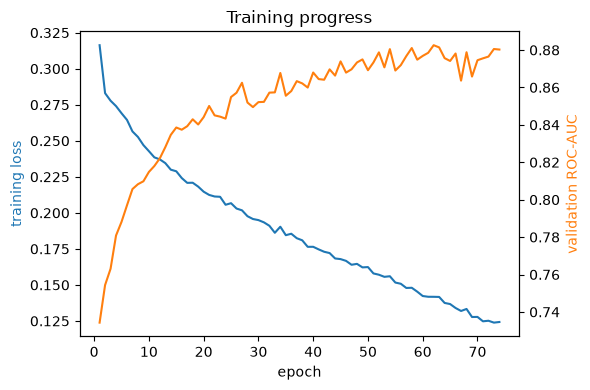

In [9]:
def plot_training_history(history):
    "Training loss and validation ROC-AUC against the epoch."
    figure, loss_axis = plt.subplots(figsize=(6, 4))
    loss_axis.plot(history["epoch"], history["train_loss"], color="tab:blue", label="train loss")
    loss_axis.set_xlabel("epoch")
    loss_axis.set_ylabel("training loss", color="tab:blue")
    auc_axis = loss_axis.twinx()
    auc_axis.plot(history["epoch"], history["validation_auc"], color="tab:orange",
                  label="validation ROC-AUC")
    auc_axis.set_ylabel("validation ROC-AUC", color="tab:orange")
    loss_axis.set_title("Training progress")
    figure.tight_layout()
    return figure


plot_training_history(history)
plt.show()

### Evaluation on the test set

With 9% actives, accuracy is uninformative: a model that calls everything inactive
scores 91%. What matters is how the ranking concentrates the actives at the top.
ROC-AUC measures the ordering as a whole, and the enrichment factor measures the
part a campaign would actually test: the hit rate in the top fraction of the
ranking divided by the hit rate of the whole set, so 1.0 means no better than
testing compounds in random order. The MCC, at the usual 0.5 cut-off, shows what
happens if the probabilities are read as labels instead.

In [10]:
def enrichment_at(labels, scores, fraction):
    "Hit rate and enrichment factor in the top fraction of the ranking."
    if not 0.0 < fraction <= 1.0:
        raise ValueError(f"fraction must lie in (0, 1], got {fraction}.")
    size = max(1, int(round(len(scores) * fraction)))
    top = np.argsort(-scores)[:size]
    hit_rate = labels[top].mean()
    baseline = labels.mean()
    return {"fraction": fraction, "compounds": size, "actives_found": int(labels[top].sum()),
            "hit_rate": hit_rate, "enrichment": hit_rate / baseline if baseline else np.nan}


def evaluate_ranking(model, graphs, fractions=TOP_FRACTIONS):
    "ROC-AUC, MCC and the enrichment table for a set of graphs."
    labels = graph_labels(graphs)
    scores = predict_probabilities(model, graphs)
    summary = {"molecules": len(labels), "active_fraction": labels.mean(),
               "roc_auc": roc_auc_score(labels, scores),
               "mcc": matthews_corrcoef(labels, (scores >= 0.5).astype(float))}
    table = pd.DataFrame([enrichment_at(labels, scores, fraction) for fraction in fractions])
    return scores, summary, table


test_scores, test_summary, test_enrichment = evaluate_ranking(model, subset(test_index))
print(f"test set: {test_summary['molecules']} molecules, "
      f"{test_summary['active_fraction']:.1%} active")
print(f"ROC-AUC {test_summary['roc_auc']:.3f}   MCC {test_summary['mcc']:.3f}")
test_enrichment.round(3)

test set: 4497 molecules, 9.1% active
ROC-AUC 0.886   MCC 0.454


,fraction,compounds,actives_found,hit_rate,enrichment
0,0.005,22,14,0.636,6.997
1,0.010,45,26,0.578,6.353
2,0.020,90,55,0.611,6.719
3,0.050,225,137,0.609,6.695
4,0.100,450,228,0.507,5.571
5,0.200,899,308,0.343,3.767


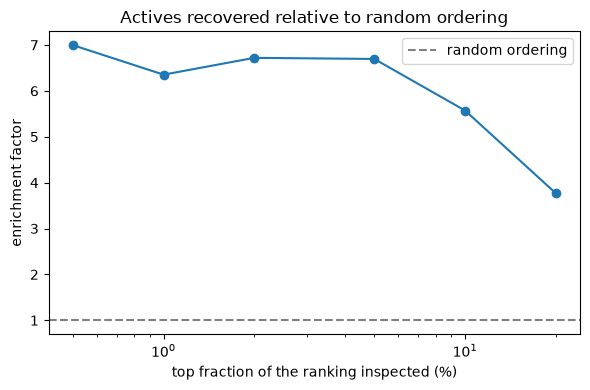

In [11]:
def plot_enrichment(enrichment_table):
    "Enrichment factor against the fraction of the ranking inspected."
    figure, axis = plt.subplots(figsize=(6, 4))
    axis.plot(100 * enrichment_table["fraction"], enrichment_table["enrichment"], marker="o")
    axis.axhline(1.0, color="gray", linestyle="--", label="random ordering")
    axis.set_xscale("log")
    axis.set_xlabel("top fraction of the ranking inspected (%)")
    axis.set_ylabel("enrichment factor")
    axis.set_title("Actives recovered relative to random ordering")
    axis.legend()
    figure.tight_layout()
    return figure


plot_enrichment(test_enrichment)
plt.show()

### Scoring new molecules

The trained model takes SMILES, builds the graphs and returns the probability of
activity, sorted from the most to the least promising. Structures that cannot be
parsed are reported rather than silently dropped. This is the function a screening
run would call on a library.

The probe below uses three first-line anti-tuberculosis drugs and one molecule with
no antitubercular activity. It is a sanity check on the model, not a benchmark: the
drugs are small, old molecules, unlike the synthetic compounds that make up a
screening deck, so this tests the model exactly where it is weakest.

In [12]:
def score_molecules(model, smiles_list):
    "Probability of activity for new molecules, most promising first."
    parsed, failed = [], []
    for smiles in smiles_list:
        molecule = Chem.MolFromSmiles(smiles)
        if molecule is None:
            failed.append(smiles)
        else:
            parsed.append((smiles, molecule))
    if failed:
        print(f"{len(failed)} SMILES could not be parsed and were skipped, e.g. {failed[0]!r}")
    if not parsed:
        raise ValueError("None of the supplied SMILES could be parsed.")

    graphs = [molecule_to_graph(molecule) for _, molecule in parsed]
    probabilities = predict_probabilities(model, graphs)
    table = pd.DataFrame({"smiles": [smiles for smiles, _ in parsed],
                          "probability_active": probabilities})
    return table.sort_values("probability_active", ascending=False).reset_index(drop=True)


probe_molecules = {
    "isoniazid (anti-TB drug)": "NNC(=O)c1ccncc1",
    "pyrazinamide (anti-TB drug)": "NC(=O)c1cnccn1",
    "ethambutol (anti-TB drug)": "CCC(CO)NCCNC(CC)CO",
    "caffeine (no antitubercular activity)": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
}
scored = score_molecules(model, list(probe_molecules.values()))
scored["molecule"] = scored["smiles"].map({v: k for k, v in probe_molecules.items()})
print(scored[["molecule", "probability_active"]].to_string(index=False))

predictions = molecule_frame.loc[test_index, [SMILES_COLUMN, LABEL_COLUMN]].copy()
predictions["probability_active"] = test_scores
predictions.sort_values("probability_active", ascending=False).to_csv(PREDICTIONS_FILE, index=False)
print(f"\ntest-set ranking written to {PREDICTIONS_FILE}")

                             molecule  probability_active
            ethambutol (anti-TB drug)        7.909313e-01
caffeine (no antitubercular activity)        4.345889e-07
          pyrazinamide (anti-TB drug)        6.654745e-08
             isoniazid (anti-TB drug)        5.293082e-12

test-set ranking written to gnn_predictions.csv


## Results, limitations and references

On the worked example (22,484 molecules, 9.1% active; 15,738 for training and
4,497 held out for testing) the model has 36,737 parameters, stopped at epoch 74
keeping the weights of epoch 62, and reached a **ROC-AUC of 0.886** on the test
set.

The figures reported here come from one run of this notebook. `RANDOM_SEED` fixes
the data split and the weight initialization, so a rerun on the same machine
reproduces them, but a different PyTorch version, operating system or number of
CPU threads changes the order in which floating-point numbers are added up. The
stopping epoch and the third decimal of each metric therefore move a little from
one machine to another; anyone rerunning the notebook should read their own
printed numbers, which will be close to these but not identical.

What the result means for a screening campaign is in the enrichment table. Testing
the top 0.5% of the ranking (22 compounds) recovers 14 actives, a 64% hit rate
against the 9.1% hit rate of the set as a whole, so **7.0 times more actives per
compound assayed**; the top 5% (225 compounds) recovers 137, still 6.7 times the
base rate. The advantage decays as more of the ranking is inspected, to 3.8 times
by the top 20%, which is the expected shape: the model is confident about a small
group and increasingly unsure after that.

The MCC of 0.454 is the other side of the same result. Reading the probabilities as
labels at the 0.5 cut-off throws away most of the ranking's value, because with 9%
actives a model that is right about the order can still misclassify many individual
compounds. The ranking is the product; the label is not.

The probe at the end marks the boundary of what the model is for. Ethambutol gets
0.79, while isoniazid and pyrazinamide get values near zero (5e-12 and 7e-8) and so
does caffeine. None of the four is in the file, and the two that score lowest are
small, polar molecules that work through mechanisms specific to mycobacteria,
unlike the larger synthetic compounds that make up the screening deck the model
learned from. A model trained on a deck learns the chemistry of that deck's
actives, which is enough to prioritize more of the same library and not enough to
judge a molecule from somewhere else. The extreme values also show the
probabilities are confident far beyond what the data supports: they order molecules
well, but should not be read as calibrated probabilities of activity.

Limitations:

- Trained on CPU with one random seed and no hyperparameter search; the hidden
  width, the number of message-passing steps and the learning rate are untuned
  defaults, and a different seed moves the metrics.
- The split is random, so a close analogue of a training molecule can appear in the
  test set. A split by molecular scaffold is the stricter alternative and would give
  a lower, more conservative estimate.
- The file keeps ten inactives per active instead of the whole screen, so the 9.1%
  active fraction in the file is an artefact of that sampling, not the 0.97% hit
  rate of the assay. The ranking metrics are relative to the file, and enrichment on
  the full screen would be measured against a much lower base rate.
- The atom features are deliberately minimal and the bonds carry no type, so a
  single and a double bond are indistinguishable to the model. Directed
  message-passing variants that featurize the bonds are the usual next step.
- `global_mean_pool` averages over atoms, so a large molecule dilutes the
  contribution of a small reactive group; sum or attention-based readouts behave
  differently.
- The model gives no account of which substructure drove a prediction; a GNN needs
  dedicated attribution methods to be interpreted.
- A primary HTS at a single concentration carries false positives and false
  negatives, and compounds the depositor marked inconclusive are excluded
  altogether, so some of what the model learns is assay artefact.
- Predictions are reliable only for molecules resembling the training set and
  require experimental confirmation.

References:

1. Oliveira, T.A.; Silva, M.P.; Maia, E.H.B.; Silva, A.M.; Taranto, A.G. Virtual
   Screening Algorithms in Drug Discovery: A Review Focused on Machine and Deep
   Learning Methods. *Drugs Drug Candidates* **2023**, 2, 311-334.
   https://doi.org/10.3390/ddc2020017
2. Gilmer, J.; Schoenholz, S.S.; Riley, P.F.; Vinyals, O.; Dahl, G.E. Neural Message
   Passing for Quantum Chemistry. *Proc. ICML* **2017**, 1263-1272.
   https://arxiv.org/abs/1704.01212
3. Kipf, T.N.; Welling, M. Semi-Supervised Classification with Graph Convolutional
   Networks. *Proc. ICLR* **2017**. https://arxiv.org/abs/1609.02907
4. Yang, K. et al. Analyzing Learned Molecular Representations for Property
   Prediction. *J. Chem. Inf. Model.* **2019**, 59, 3370-3388.
   https://doi.org/10.1021/acs.jcim.9b00237
5. Stokes, J.M. et al. A Deep Learning Approach to Antibiotic Discovery. *Cell*
   **2020**, 180, 688-702. https://doi.org/10.1016/j.cell.2020.01.021
6. Yasir, M.; Park, J.; Han, E.-T.; Park, W.S.; Han, J.-H.; Chun, W. Drug
   Repositioning via Graph Neural Networks: Identifying Novel JAK2 Inhibitors from
   FDA-Approved Drugs through Molecular Docking and Biological Validation.
   *Molecules* **2024**, 29, 1363. https://doi.org/10.3390/molecules29061363
7. Fey, M.; Lenssen, J.E. Fast Graph Representation Learning with PyTorch Geometric.
   *ICLR Workshop on Representation Learning on Graphs and Manifolds* **2019**.
   https://arxiv.org/abs/1903.02428
8. PubChem BioAssay AID 1626: primary screen for inhibitors of *Mycobacterium
   tuberculosis* H37Rv (Southern Research Institute).
   https://pubchem.ncbi.nlm.nih.gov/bioassay/1626
9. Kim, S. et al. PubChem 2023 update. *Nucleic Acids Res.* **2023**, 51,
   D1373-D1380. https://doi.org/10.1093/nar/gkac956
10. RDKit: Open-source cheminformatics. https://www.rdkit.org